
### Term Project
#### Milestone 3


For this project I will be utilizing the [IBM HR Analytics Employee Attrition & Performance Dataset](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) from Kaggle.

### Milestone 1

#### Business Problem


This project will focus on a significant issue for all companies - employee turnover. As a previous software engineer, and now a Software Development Manager, this is a very relevant issue that is quite interesting to me. High employee turnover is a significant financial burden on companies; replacing an employee can cost between 1.5 to 2 times that employee's annual salary. This is more than just the cost of hiring a new employee, since attrition also leads to a loss of institutional knowledge and can affect team morale. In some cases, losing high value employees means a loss of specific program knowledge, and in fields like software engineering, losing an integral engineer may mean loss of understanding an entire code base or application. In these cases, the employee is truly invaluable, as there is no way to replace the level of knowledge and intimacy that employee had with the codebase. Companies can no longer simply worry about trying to make changes after a reactive exit interview, but instead should be proactive in retaining good employees. What this project will focus on is trying to identify tipping points, like pay disparity, overtime frequency, and commute distance, in leading to an employee's decision to leave the company. 



#### Target


The target for this model will be a binary classification model for attrition- either yes or no. By predicting the probability of an employee leaving, managers and HR business partners would be able to prioritize interventions like conducting stay interviews, salary adjustments or possibly remote work options for anyone listed as a *high-risk* individual before they submit their resignation.

In [41]:
import pandas as pd

# load the Employee Attrition data into a dataframe
attrition = pd.read_csv('Employee_Attrition.csv')

# display the first few rows of data
# attrition.head(3)

#### Graphical Analysis

To help understand why people leave a company, visualizing relationships between the features and the attrition target will assist in answering this question.

- **Graph 1 Box Plot: Monthly Income vs Attrition**
  - help determine if there is a disparity in pay between those who stay and those who leave
- **Graph 2 Stacked Bar Chart: Overtime vs Attrition**
  - help visualize if employees are being burned out with overtime and causing them to quit
- **Graph 3 Correlation Heatmap: Numeric Features**
  - help identify any multicollinearity (like Age and years at company) and see which variables have the strongest linear relationship with attrition.
  - Removing constant or non-informative fields will improve the sensitivity of the model and will help to ensure that the model will stay focused on high-variance signals such as *MonthlyIncome* and *Age*.
  - First, encode my target variable of *Attrition* to allow me to better assess numeric relationships with the target
- **Graph 4 Violin Plot: Attrition Segmented by Marital Status**
  - This will help to visualize if employees are more likely to quit if they are younger or single compared to someone married and older, and considered *more settled* in their careers.

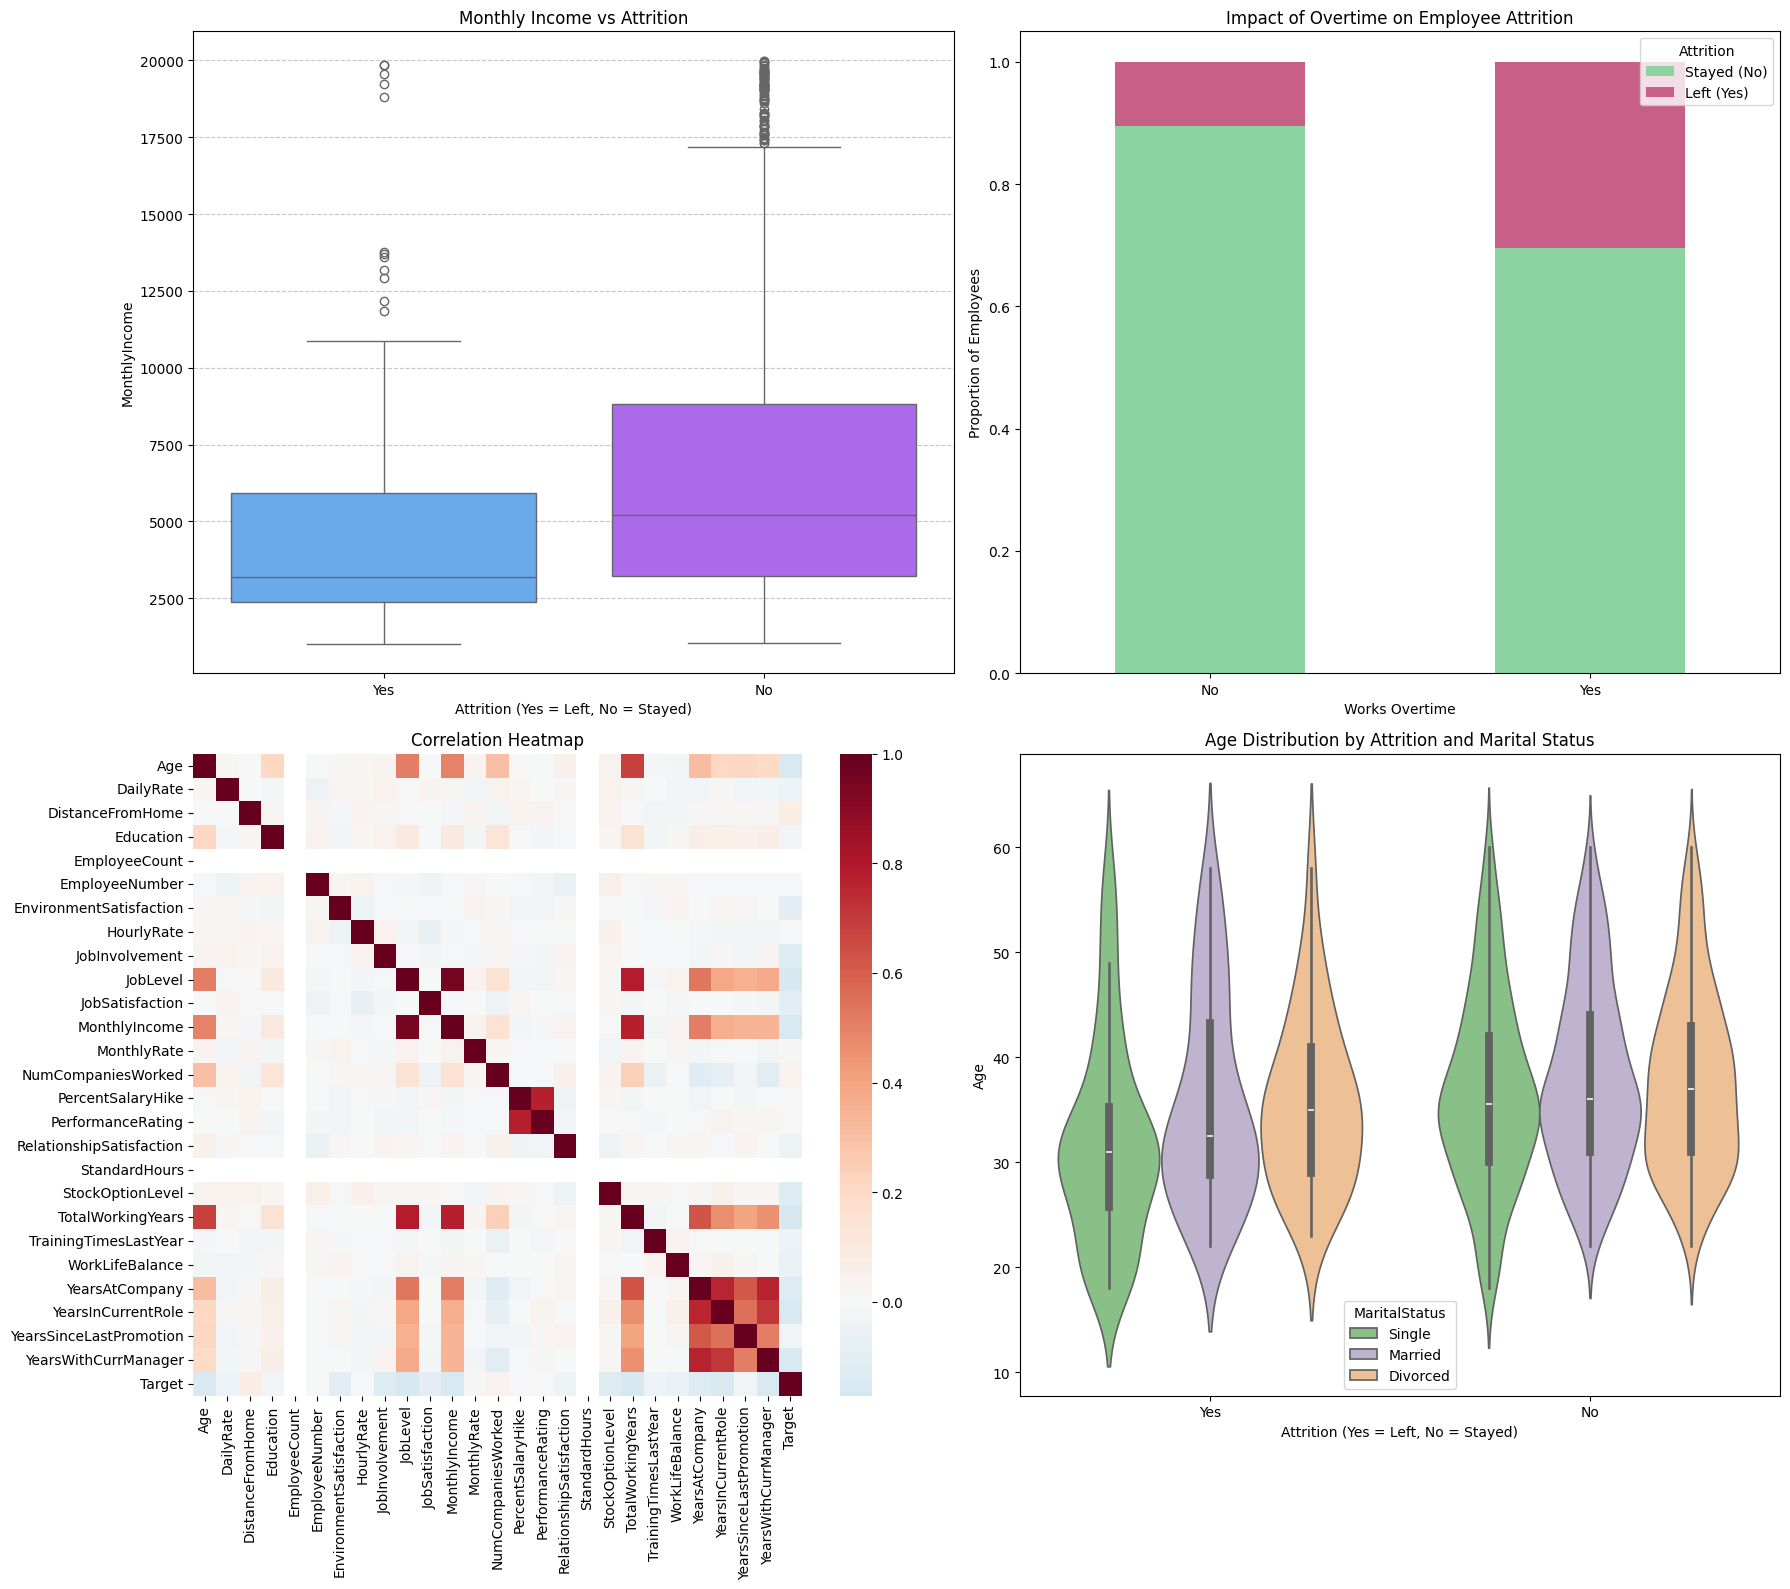

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# prep for heatmap
attrition['Target'] = attrition['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)
numeric_attrition = attrition.select_dtypes(include=[np.number])
corr_matrix = numeric_attrition.corr()

# Create a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(18, 16))

# Graph 1 Box Plot: Income vs Attrition
sns.boxplot(ax=axes[0, 0], data=attrition, x='Attrition', y='MonthlyIncome', hue="Attrition", palette='cool', legend=False)
axes[0, 0].set_title('Monthly Income vs Attrition')
axes[0, 0].set_xlabel('Attrition (Yes = Left, No = Stayed)')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)

# Graph 2 Stacked Bar Chart: Overtime
overtime_attrition = pd.crosstab(attrition['OverTime'], attrition['Attrition'], normalize='index')
overtime_attrition.plot(kind='bar', stacked=True, color=['#8DD3A2', '#C75F87'], ax=axes[0, 1])
axes[0, 1].set_title('Impact of Overtime on Employee Attrition')
axes[0, 1].set_xlabel('Works Overtime')
axes[0, 1].set_ylabel('Proportion of Employees')
axes[0, 1].legend(title='Attrition', labels=['Stayed (No)', 'Left (Yes)'], loc='upper right')
axes[0, 1].tick_params(axis='x', rotation=0)

# Graph 3 Heatmap
sns.heatmap(corr_matrix, ax=axes[1, 0], annot=False, cmap='RdBu_r', center=0)
axes[1, 0].set_title('Correlation Heatmap')

# Graph 4 Violin Plot: Age & Marital Status
sns.violinplot(ax=axes[1, 1], data=attrition, x='Attrition', y='Age', hue='MaritalStatus', palette='Accent')
axes[1, 1].set_title('Age Distribution by Attrition and Marital Status')
axes[1, 1].set_xlabel('Attrition (Yes = Left, No = Stayed)')

# adjust layout to prevent overlapping titles
plt.tight_layout()
plt.show()

#### Graphical Analysis Overview/Conclusion

The graphical analysis of this IBM Attrition dataset  identifies several notable patterns that serve as foundational indicators for predicting employee turnover. These graphs provided insight pointing to employee turnover rates not just being random occurrences but a multi-faceted business problem that is driven by specific demographic, operational, and financial indicators. The primary variable identified during this initial analysis is the intersection of pay and workload. By encoding the target and pruning constant feature, I have established that *Total Working Years*, *Monthly Income*, and *Overtime* are the most meaningful predictors. The Monthly Income box plot confirmed that employees who leave companies tend to do so when they are at lower salary bands which suggests that companies lose talentend employees to competitors offering higher entry-level or mid-level wages. It is also known, in some fields (like software engineering), that the only way to get a promotion is to job hop. The Overtime Stacked bar chart also provided clear evidence of burnout being a huge reason for employee attrition. Employees who work overtime had a significant increase in attrition rates. To ensure covering of the demographic portion, the Violin Plot and Marital Status revealed that younger, single employees are more likely to leave a job. This could indicate that companies are not investing in the early career development of their employees enough. The correlation heatmap indicated redundant variables in job level, total working years, and monthly income which will need to be considered as a single variable of *Seniority* to avoid the statistical noise of multicollinearity.

Based on these insights the proposed model will focus on a multi-pronged approach to indentifying turnover risk. High-risk individuals for attrition have been identified as younger, lower-paid and frequently working overtime. In the modeling phase recall will be important to ensure that the model will be sensitive enough to catch these high risk employees even if employees who are not planning to leave are flagged for HR intervention. This strategy will help the HR department to maximize their return on investment for retention efforts, which will directly address the underlying business problem of high replacement costs and loss of institutional knowledge. 

### Milestone 2 - Data Preparation

This phase is focused on converting raw categorical data into a format that will be suitable for use with machine learning algorithms.

**Feature Pruning**

I will begin by removing fields that will not add any beneficial information to the model. Based on my initial review I believe the columns that I will drop are: EmployeeCount,Over18, StandardHours, EmployeeNumber, and Attrition. The first three have constant values across all the rows, with no variance, which means there is nothing for the model to learn or gain from them. The *EmployeeNumber* is a unique identifier for each employee, but it could lead to overfitting, since the model may begin to recognize specific IDs rather than learning the patterns. I will remove *Attrition* since I have now encoded it before creating my correlation heatmap and I do not want to have the duplicated column here as it will create noise in the model.

In [43]:
# drop constant or non-informative fields
# StandardHours, EmployeeCount, and Over18 have zero variance
# EmployeeNumber is just a unique ID
# Attrition- I already encoded this so I will remove the duplicate column
drop_columns = ['StandardHours', 'EmployeeCount', 'Over18', 'EmployeeNumber', 'Attrition']
attrition_cleaned = attrition.drop(columns=drop_columns)

print(f"Columns dropped: {drop_columns}")

Columns dropped: ['StandardHours', 'EmployeeCount', 'Over18', 'EmployeeNumber', 'Attrition']


Removing these constant fields provide noise reduction which will increase the baseline significance, $\alpha$, of the remaining features and will allow the model's sensitivity, $\beta$, to focus on actual behavioral triggers like overtime.

**Handling Missing Data**

To ensure data integrity I will need to validate that there are no null, NaN, None or empty string values that would negatively affect the model.

In [44]:
# audit for missing values to ensure data integrity
print(f"Null/NaN/None or empty values: {attrition_cleaned.isnull().sum().max()}")

Null/NaN/None or empty values: 0


This check shows there are no null or empty values across this dataset. This is what I expect since this is a dataset from Kaggle and is a fictional dataset created by IBM data scientists. Since there are no null values across all 1,470 records no row deletion or value imputation is required.

**Feature Engineering**

Feature engineering is done to help increase the sensitivity of a model by capturing complex relationships in a single variable. First, I will capture the loyalty of an employee. Company loyalty is still very strong for some people, especially among the older generation and, typically, employees who have spent all 10 years of their working years at one company tend to have a different attrition risk than someone who has only spent 10 years out of 30 years there. The value I'm looking to capture is something like tenure density. I will create a loyalty ratio feature.
$$LoyaltyRatio = \frac{YearsAtCompany}{TotalWorkingYears}$$


In [45]:
# engineer a new feature: LoyaltyRatio
# adding a small constant to denominator to avoid division by zero
attrition_cleaned['LoyaltyRatio'] = attrition_cleaned['YearsAtCompany'] / (attrition_cleaned['TotalWorkingYears'] + 1)

# attrition_cleaned.head(2)

In [46]:
# binary encoding for OverTime
attrition_cleaned['OverTime'] = attrition_cleaned['OverTime'].apply(lambda x: 1 if x == 'Yes' else 0)
print("Encoded OverTime")
# attrition_cleaned.head(2)

Encoded OverTime


**Consolidation**

Through the correlation heatmap, I can see that *JobLevel*, *MonthlyIncome*, and *TotalWorkingYears* variables are highly correlated and will distract the model due to the redundancy of the data. To combat this I will consolidate these variables into what these three variables are really representing, *Seniority*. Keeping all of these variables can lead to overfitting since the model may over-emphasize this dimension of an employee's seniority. 

I will create a single value of seniority (*SeniorityIndex*) to capture these three variables and capture a standard score (Z-Score) for them for each employee.

$$SeniorityIndex = \frac{z(JL) + z(MI) + z(TWY)}{3}$$

This should help to encapsulate the underlying essence of someone's seniority while trying to smooth possible outliers- like a younger person with a higher salary, or an older person who is newer to the workforce and has a more junior level position. 

**FROM FEEDBACK: Justification for SeniorityIndex Consolidation:** 

*Why not PCA?* PCA creates "Principal Components" that are mathematically optimal but uninterpretable. In an HR context, a manager can understand a "Seniority Index" (a blend of pay and tenure), but they cannot understand "Component 1."

*Why not Regularization?* While Lasso (L1) could zero out redundant features, it might pick one (e.g., JobLevel) and discard others that contain unique "Signal."

*Conclusion:* The SeniorityIndex is a domain-driven feature that preserves the collective signal of career progression while maintaining the explainability required for business decision-making.

In [50]:
# --- FROM FEEDBACK: PRE-SPLIT: TYPE CASTING & DUMMY CREATION ---
#  Create dummy variables and cast to 0/1 integers
attrition_final = pd.get_dummies(attrition_cleaned, columns=[
    'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus'
], drop_first=True).astype(int)

# --- FROM FEEDBACK: DEFINE X AND Y ---
# Drop the Target and the original string column
X = attrition_final.drop(columns=['Target', 'Attrition'], errors='ignore')
y = attrition_final['Target']

# --- FROM FEEDBACK: THE TRAIN/TEST SPLIT BEFORE StandardScaler (PREVENTS DATA LEAKAGE) ---
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- FROM FEEDBACK: POST-SPLIT: PREPROCESSING & FEATURE ENGINEERING ---
from sklearn.preprocessing import StandardScaler

# initialize scalers
s_scaler = StandardScaler() # Specifically for the Index components
scaler = StandardScaler()   # For all other numeric features

# define groups
seniority_cols = ['JobLevel', 'MonthlyIncome', 'TotalWorkingYears']
numeric_features = [
    'Age', 'DailyRate', 'DistanceFromHome', 'Education', 'HourlyRate', 
    'JobInvolvement', 'JobSatisfaction', 'MonthlyRate', 'NumCompaniesWorked', 
    'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 
    'StockOptionLevel', 'TrainingTimesLastYear', 'WorkLifeBalance', 
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 
    'YearsWithCurrManager', 'LoyaltyRatio'
]

# create SeniorityIndex (Fit on Train, Transform Test)
X_train_s_scaled = s_scaler.fit_transform(X_train[seniority_cols])
X_test_s_scaled = s_scaler.transform(X_test[seniority_cols])

X_train['SeniorityIndex'] = X_train_s_scaled.mean(axis=1)
X_test['SeniorityIndex'] = X_test_s_scaled.mean(axis=1)

# drop original seniority components to prevent multicollinearity
X_train = X_train.drop(columns=seniority_cols)
X_test = X_test.drop(columns=seniority_cols)

# scale all other numeric features (fit on train, transform test)
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

print("Data preparation complete. All steps reordered to prevent snooping and Professor Feedback addressed")

Data preparation complete. All steps reordered to prevent snooping and Professor Feedback addressed


## Milestone 3

This section focuses on selecting, building, and evaluating a model. The requirement is to train and evaluate at least one model in this milestone. Include a step-by-step write up for performing each of the steps. Include explainations/justifications for model(s) selction and evaluation metric(s) chosen. Proivde a short overview/conclusion of the insights gained from model building/evaluation.

### Model Selection

The problem I am tackling is a binary issue, stay or leave, so I need to chose a classification model. I will test out two different models that have different mathematical approaches.

**Model 1: Logistic Regression**

For the first model I will use a *Logistic Regression* model for my baseline. This is an industry standard for binary classification and should show exactly how each feature, like my SeniorityIndex, increases or decreases the odds of attrition. This should help provide insight into how a factor, like overtime, will increase the odds of someone quitting. This model provides high transparency, which is essential for HR to justify their intervention strategies to leadership or to help guide managers.

**Model 2: Random Forest Classifier**

I will then test with the *Random Forest Classifier* since it is able to capture non-linear relationships and feature interactions that the Logistic Regression cannot. For example, a high salary may prevent attrition for some staff, but if it is combined with many overtime hours plus a long commute that high salary may not be enough to retain the employee. A Random Forest is able to see these combinations with the tree-based structure. This model is highly resistant to outliers and will automatically provide a feature importance ranking which will help in identifying which variables are the strongest drivers of attrition across the company.

#### Why not another model?

I chose these two models because I need to understand which features play an important part in retention and attrition. Models like KNN tend to be less predictive when dealing with human behavior since it is distance-based. Support Vector Machines are powerful, but are black boxes which won't provide the explainability that I need for this business case. Something like Naive Bayes assumes feature independence and would most likely lead to poor performance since I already know features like Age, JobLevel and YearsAtCompany have a natural relation.

### Evaluation Metrics

This dataset shows roughly 84% of employees stayed, why only 16% left. If a model predicted that no one would ever leave then it would be 84% accurate. It would also be 0% useful because it would not identify a single at risk employee. This is why I must prioritize metrics that will specifically look at the minority class (the employees who leave). Due to this 84/16 class imbalance it is important to note that an Accuracy score is insufficient for evaluation. 

**Primary Metric:** F1-Score

**Justification:** The F1-score is the harmonic mean of Precision and Recall. It penalizes the model for being "lazy" and just guessing the majority class. Through F1-Score optimization I can ensure that the model is catching a significant numer of at-risk employees without overwhelming the HR department with false alarms. It will provide a more robust assessment of the model's performance on the minority class than accuracy will.

**Secondary Metric:** Recall (Sensitivity)

**Justification:** Recall measures the ability to find the actual at risk employees. It will answer the question: *Out of all the people who actually left, how many did the model correctly catch?* In business, the cost of miss is high. If an integral engineer leaves and the model failed to flag them (False Negative), the company would lose institutional knowledge and face high replacement costs. In HR, the cost of a "False Negative" (failing to identify an employee who is about to quit) is much higher than a "False Positive" (reaching out to someone who was going to stay). Recall measures the model's ability to catch the actual employees who attrit. Recall is a priority as it would be better to have a false alarm and reach out to a happy employee, rather than miss on reaching out to an employee who is truly debating leaving.

Together these metrics will ensure that the model is sensitive enough to catch depatures (Recall), while remaining reliable enough for leadership to trust the predictions (F1-Score). 

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# initialize models
lr_model = LogisticRegression(max_iter=1000, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# fit models on training data
lr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Models trained successfully.")

Models trained successfully.



--- Logistic Regression Performance ---
              precision    recall  f1-score   support

           0       0.89      0.96      0.92       247
           1       0.65      0.36      0.47        47

    accuracy                           0.87       294
   macro avg       0.77      0.66      0.70       294
weighted avg       0.85      0.87      0.85       294

Confusion Matrix (Raw Counts):
[[238   9]
 [ 30  17]]


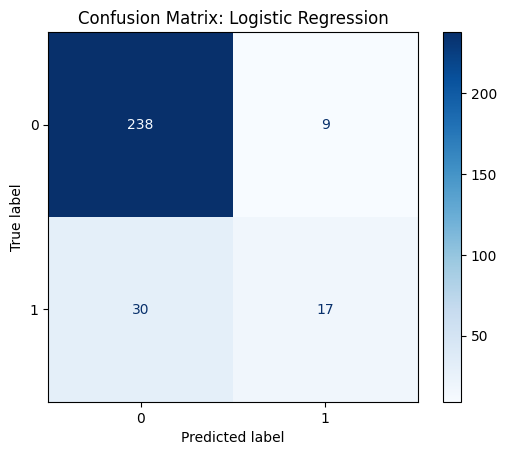


--- Random Forest Performance ---
              precision    recall  f1-score   support

           0       0.85      0.98      0.91       247
           1       0.50      0.11      0.18        47

    accuracy                           0.84       294
   macro avg       0.68      0.54      0.54       294
weighted avg       0.80      0.84      0.79       294

Confusion Matrix (Raw Counts):
[[242   5]
 [ 42   5]]


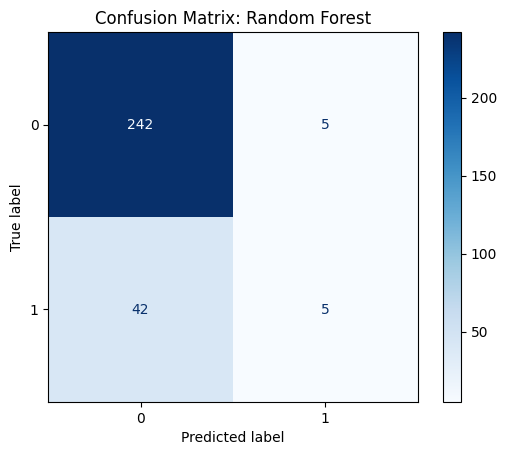

In [49]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# predict and evaluate
models = {"Logistic Regression": lr_model, "Random Forest": rf_model}

for name, model in models.items():
    preds = model.predict(X_test)
    print(f"\n--- {name} Performance ---")
    
    # print classification report: provides Precision, Recall, and F1-score
    print(classification_report(y_test, preds))
    
    # this provides the raw numbers (TP, FP, TN, FN)
    print("Confusion Matrix (Raw Counts):")
    print(confusion_matrix(y_test, preds))
    
    # create the visual representation 
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
    plt.title(f"Confusion Matrix: {name}")
    plt.show()

**Why use a confusion matrix?**
In this project, the raw numbers are very important because of the Class Imbalance.

True Negatives (Top Left): Employees the model correctly guessed would stay.

False Positives (Top Right): Employees the model thought would leave, but they stayed.

False Negatives (Bottom Left): CRITICAL. Employees the model thought would stay, but they actually left. As a manager, this is the number you want to minimize.

True Positives (Bottom Right): Employees the model correctly identified as "at risk" of leaving.


## Conclusion of insights gained from model building/evaluation

Both models have respectable overall accuracy, 87% and 84%. However, since the dataset is imbalance (247 people stayed vs 47 left in the test set), the models are naturally *better* at predicting the majority class (employees who stayed).
Logistic regression was significantly more useful because it actually attempted to find the employees who attrited. The Random Forest model is playing it safe and guessing that almost everyone will stay to keep the accuracy value high. The intial evaluation reveals that the *Logistic Regression* model outperformed the *Random Forest* in predicting employee attrition across all critical metrics. While both models maintain high accuracy due to the majority class (employees who stayed), the *Logistic Regression* achieved a significantly higher Recall (0.36) compared to the Random Forest (0.11). 
The high number of false negatives in the Random Forest suggests that the tree-based model is struggling with the 84/16 class imbalance. In contrast, the Logistic Regression model was able to correctly identify nearly 40% of the at-risk employees. 

| Metric | Logisitic Regression | Random Forest | Winner |
| -- | -- | -- | -- |
| Recall | 0.36 | 0.11 | Logistic |
| Precision | 0.65 | 0.50 | Logistic |
| F1-Score | 0.47 | 0.18 | Logistic |
| False Negatives (Misses) | 30 | 42 | Logistic |

Logistic Regression won during this first test since linear relationships, like my Seniority Index)is likely the strongest signals. The Random Forest model tends to require more data or hyperparameter tuning to overcome the class imbalance. As it is now, the Random Forest essentially ignored the employees who left, missing 42 out of the 47 who attrited. 
As a Software Development Manager, right now I would use the Logisitic Regression model as it is currently the more viable tool. It was able to catch the 17 at risk individuals that could be prioritized for retention interviews. However, the overall low F1 scores indicate that I should investigate threshold tuning or synthetic minority over-sampling technique and investigate hyperparemeter tuning to be able ot better balance the model's sensitivity without increasing false alarms. 